In [1]:
import pandas as pd
import numpy as np

# Load raw dataset
df = pd.read_csv('../data/raw_customer_data.csv')

# Clean numeric column & target label
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce').fillna(0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Feature Engineering
df['Avg_Monthly_Charge_Ratio'] = np.where(df['tenure'] > 0, df['TotalCharges'] / df['tenure'], df['MonthlyCharges'])
df['Tenure_Group'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 48, 60, 100], 
                            labels=['0-1 yr', '1-2 yrs', '2-4 yrs', '4-5 yrs', '5+ yrs'])

df[['customerID', 'tenure', 'Tenure_Group', 'MonthlyCharges', 'TotalCharges', 'Avg_Monthly_Charge_Ratio']].head()

,customerID,tenure,Tenure_Group,MonthlyCharges,TotalCharges,Avg_Monthly_Charge_Ratio
0,7590-VHVEG,1,0-1 yr,29.85,29.85,29.850000
1,5575-GNVDE,34,2-4 yrs,56.95,1889.50,55.573529
2,3668-QPYBK,2,0-1 yr,53.85,108.15,54.075000
3,7795-CFOCW,45,2-4 yrs,42.30,1840.75,40.905556
4,9237-HQITU,2,0-1 yr,70.70,151.65,75.825000


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['customerID', 'Churn'])
y = df['Churn']

# One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (5634, 35)
Testing shape: (1409, 35)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Fit models
log_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

log_reg.fit(X_train_scaled, y_train)
rf_clf.fit(X_train, y_train)

# Evaluate
print("=== LOGISTIC REGRESSION ===")
print(classification_report(y_test, log_reg.predict(X_test_scaled)))
print("ROC-AUC:", round(roc_auc_score(y_test, log_reg.predict_proba(X_test_scaled)[:, 1]), 4))

print("\n=== RANDOM FOREST ===")
print(classification_report(y_test, rf_clf.predict(X_test)))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_clf.predict_proba(X_test)[:, 1]), 4))

=== LOGISTIC REGRESSION ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8425

=== RANDOM FOREST ===
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

ROC-AUC: 0.822


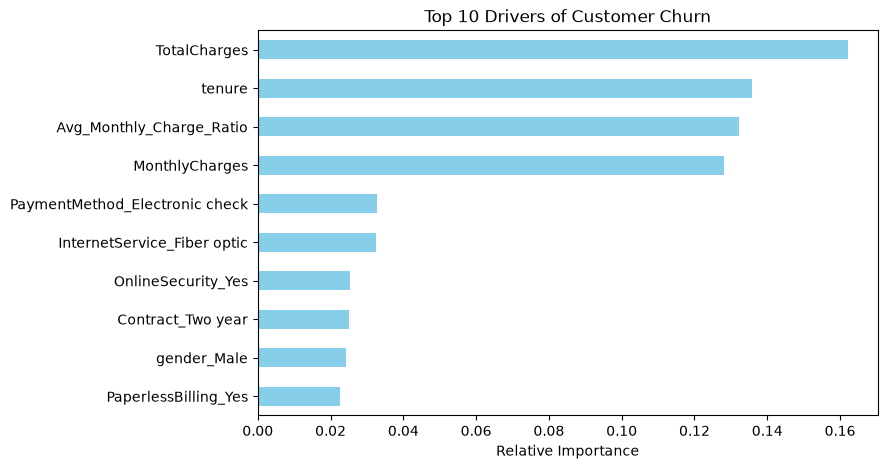

=== CUSTOMER RISK SEGMENTATION BREAKDOWN ===
Risk_Segment
Low Risk (0-30%)        871
Medium Risk (30-70%)    422
High Risk (70-100%)     116
Name: count, dtype: int64


In [4]:
import matplotlib.pyplot as plt

# 1. Feature Importance Plot (Random Forest)
importances = rf_clf.feature_importances_
feature_names = X_encoded.columns
rf_importances = pd.Series(importances, index=feature_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
rf_importances.plot(kind='barh', color='skyblue')
plt.title('Top 10 Drivers of Customer Churn')
plt.gca().invert_yaxis()
plt.xlabel('Relative Importance')
plt.show()

# 2. Risk Segmentation (Logistic Regression Probabilities)
# Predict churn probabilities on test set
churn_probs = log_reg.predict_proba(X_test_scaled)[:, 1]

test_results = X_test.copy()
test_results['Actual_Churn'] = y_test
test_results['Churn_Probability'] = churn_probs

# Assign Risk Tiers based on probability thresholds
def assign_risk_tier(prob):
    if prob < 0.30:
        return 'Low Risk (0-30%)'
    elif prob < 0.70:
        return 'Medium Risk (30-70%)'
    else:
        return 'High Risk (70-100%)'

test_results['Risk_Segment'] = test_results['Churn_Probability'].apply(assign_risk_tier)

# Display Segment Breakdown
print("=== CUSTOMER RISK SEGMENTATION BREAKDOWN ===")
print(test_results['Risk_Segment'].value_counts())